# Многомерни данни и извадъчна геометрия

Използваме данните за червено вино от предходното упражнение. Работим с цялата извадка, без разделяне на обучаващи и тестови данни. Файлът `winequality_red.csv` трябва да е в подпапка `data`.

Всяка задача съдържа изчислителна и графична част. Използвайте `np.allclose` за сравнение на числени резултати. За стандартни отклонения и ковариации използвайте знаменател $n-1$, тоест `ddof=1`.

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

plt.rcParams.update({
    'font.family': 'DejaVu Sans',
    'font.size': 11,
    'axes.spines.top': False,
    'axes.spines.right': False,
    'axes.titleweight': 'bold',
    'figure.dpi': 110,
})

blue = '#2563eb'
orange = '#ea580c'
teal = '#0f766e'
gray = '#64748b'

## 1. Матрица на данните

Нека $x_{ij}$ е стойността на $j$-тата променлива за $i$-тото вино. Матрицата на данните е $X=(x_{ij})\in\mathbb R^{n\times p}$. Редовете са наблюдения, а колоните са вектори от измервания. Средната стойност и извадъчното стандартно отклонение на колона $j$ са

$$\bar x_j=\frac1n\sum_{i=1}^n x_{ij},\qquad
s_j=\sqrt{\frac1{n-1}\sum_{i=1}^n(x_{ij}-\bar x_j)^2}.$$

**Задача 1а.** Заредете файла с разделител `;`, заменете интервалите в имената с `_` и оставете по един екземпляр от напълно еднаквите редове, както в предходното упражнение. Изберете `fixed_acidity`, `pH`, `density` и `alcohol`. Запишете таблицата като `data`, а числовата матрица като `X`. Определете $n,p$, средните стойности и стандартните отклонения.

In [3]:
wine = pd.read_csv('data/winequality_red.csv', sep=';')
wine.columns = [name.replace(' ', '_') for name in wine.columns]
wine = wine.drop_duplicates().reset_index(drop=True)

variables = ['fixed_acidity', 'pH', 'density', 'alcohol']
labels = ['Киселинност', 'pH', 'Плътност', 'Алкохол']
data = wine[variables]
X = data.to_numpy()
n, p = X.shape

means = X.mean(axis=0)
s = X.std(axis=0, ddof=1)
print('Наблюдения:', n, 'Променливи:', p)
pd.DataFrame({'Средна стойност': means, 'Стандартно отклонение': s},
             index=variables)

Наблюдения: 1359 Променливи: 4


,Средна стойност,Стандартно отклонение
fixed_acidity,8.310596,1.736990
pH,3.309787,0.155036
density,0.996709,0.001869
alcohol,10.432315,1.082065


**Задача 1б. Визуализация.** Постройте матрица от диаграми на разсейване, с хистограми по диагонала. Може да използвате `pd.plotting.scatter_matrix`. Посочете двойки с положителна, отрицателна и слаба линейна връзка. Тук точките изобразяват вина, а не вектори на колони.

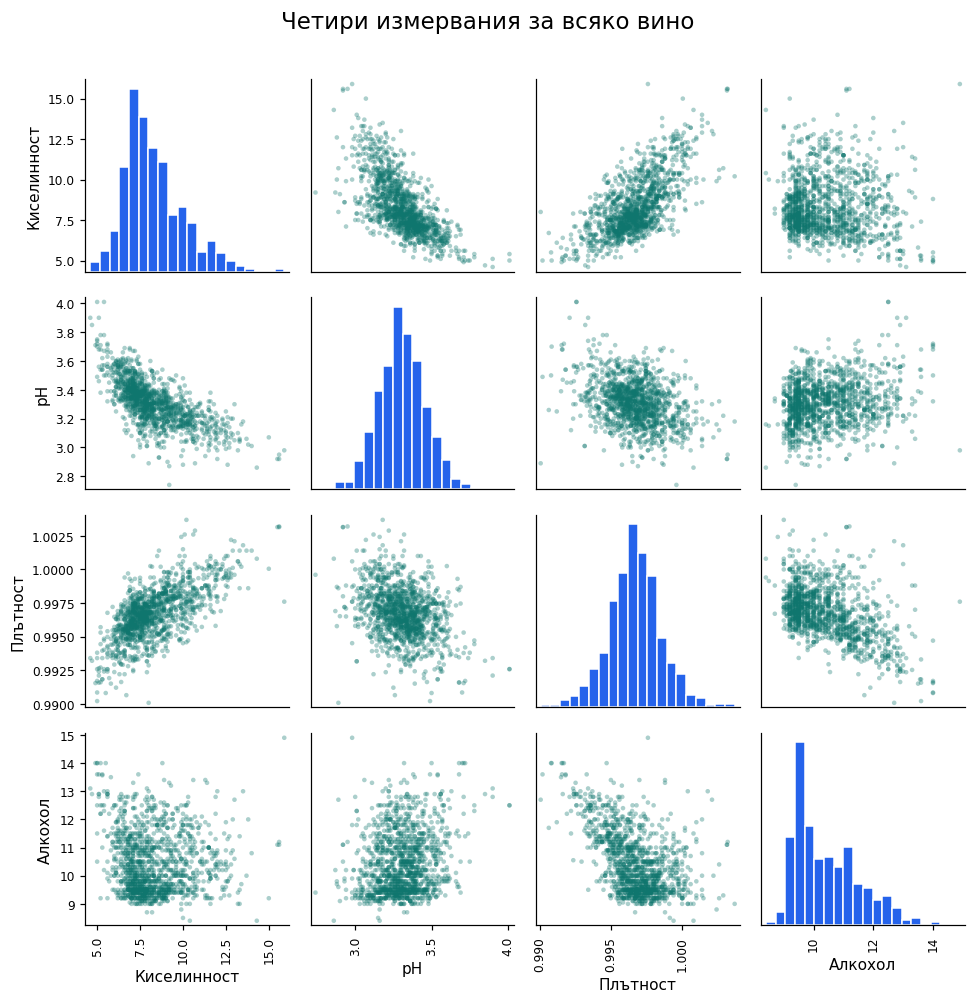

In [4]:
plot_data = data.copy()
plot_data.columns = labels
axes = pd.plotting.scatter_matrix(
    plot_data, figsize=(9, 9), diagonal='hist', color=teal, alpha=0.35,
    hist_kwds={'color': blue, 'edgecolor': 'white', 'bins': 20}
)
for ax in axes.flat:
    ax.tick_params(labelsize=8)
    ax.xaxis.label.set_size(10)
    ax.yaxis.label.set_size(10)

plt.suptitle('Четири измервания за всяко вино', fontsize=15, y=1.01)
plt.tight_layout()
plt.show()

## 2. Ковариационна и корелационна матрица

Центрираната матрица $Z$ има елементи $z_{ij}=x_{ij}-\bar x_j$. Ковариационната матрица $S=(s_{jk})$ и корелационната матрица $R=(r_{jk})$ се определят чрез

$$S=\frac{Z^\top Z}{n-1},\qquad
s_{jk}=\frac1{n-1}\sum_{i=1}^n z_{ij}z_{ik},\qquad
r_{jk}=\frac{s_{jk}}{s_js_k}.$$

Имаме $s_{jj}=s_j^2$ и $r_{jj}=1$. Корелацията е определена за колони с ненулево стандартно отклонение.

**Задача 2а.** Пресметнете $Z,S,R$ с NumPy. Проверете, че сумата на всяка колона на $Z$ е нула. Сравнете резултатите с `data.cov()` и `data.corr()`.

In [5]:
Z = X - means
S = Z.T @ Z / (n - 1)
R = S / np.outer(s, s)

print('Суми на отклоненията:', np.allclose(Z.sum(axis=0), 0))
print('Ковариации:', np.allclose(S, data.cov().to_numpy()))
print('Корелации:', np.allclose(R, data.corr().to_numpy()))
pd.DataFrame(R, index=variables, columns=variables)

Суми на отклоненията: True
Ковариации: True
Корелации: True


,fixed_acidity,pH,density,alcohol
fixed_acidity,1.000000,-0.686685,0.670195,-0.061596
pH,-0.686685,1.000000,-0.355617,0.213418
density,0.670195,-0.355617,1.000000,-0.504995
alcohol,-0.061596,0.213418,-0.504995,1.000000


**Задача 2б. Визуализация.** Представете $S$ и $R$ като топлинни карти с `imshow`. Запишете стойността във всяка клетка. За $R$ използвайте цветна скала от $-1$ до $1$. Обяснете разликата между диагоналите на двете матрици.

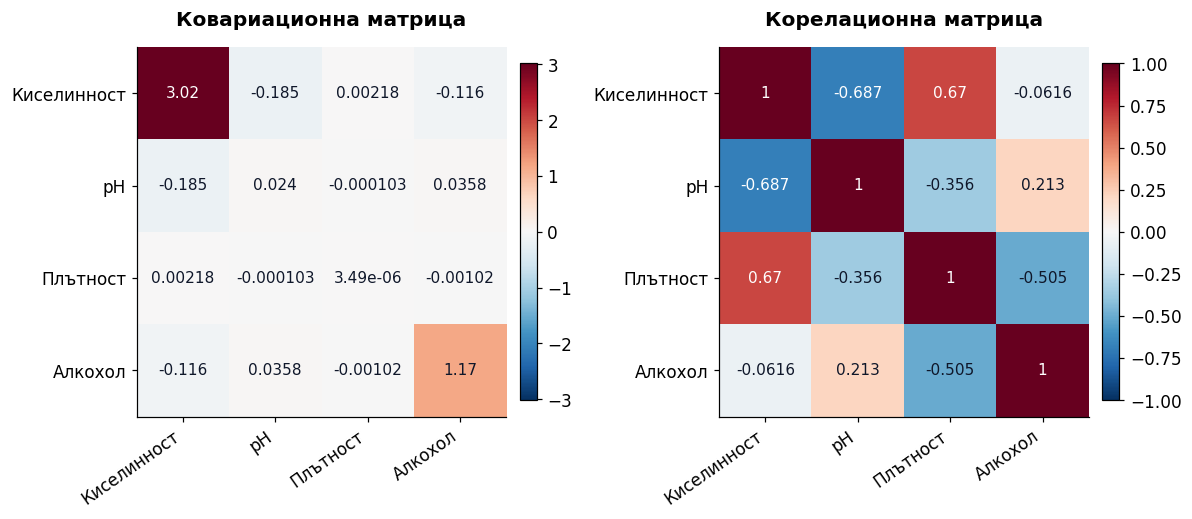

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.8))
matrices = [S, R]
titles = ['Ковариационна матрица', 'Корелационна матрица']

for ax, matrix, title in zip(axes, matrices, titles):
    limit = np.abs(matrix).max()
    image = ax.imshow(matrix, cmap='RdBu_r', vmin=-limit, vmax=limit)
    ax.set_xticks(range(p), labels, rotation=35, ha='right')
    ax.set_yticks(range(p), labels)
    ax.set_title(title, pad=14)
    for j in range(p):
        for k in range(p):
            text_color = '#0f172a'
            if abs(matrix[j, k]) > 0.55 * limit:
                text_color = 'white'
            ax.text(k, j, f'{matrix[j, k]:.3g}', ha='center', va='center',
                    color=text_color, fontsize=10)
    fig.colorbar(image, ax=ax, shrink=0.8, pad=0.03)

plt.tight_layout()
plt.show()

## 3. Проекции: пример с две наблюдения

За вектори $\mathbf a,\mathbf b\in\mathbb R^m$ скаларното произведение и евклидовата норма са

$$\mathbf a^\top\mathbf b=\sum_{i=1}^m a_ib_i,\qquad
\|\mathbf a\|=\sqrt{\mathbf a^\top\mathbf a}.$$

При $\mathbf a\ne\mathbf0$ ортогоналната проекция на $\mathbf x$ върху направлението на $\mathbf a$ е

$$\operatorname{proj}_{\mathbf a}\mathbf x
=\frac{\mathbf x^\top\mathbf a}{\mathbf a^\top\mathbf a}\mathbf a.$$

За непостоянен вектор $\mathbf x=(x_1,\ldots,x_m)^\top$ и вектор $\mathbf1\in\mathbb R^m$ от единици дефинираме

$$\bar x=\frac1m\sum_{i=1}^m x_i,\quad
\mathbf q=\frac{\mathbf1}{\sqrt m},\quad
\mathbf d=\mathbf x-\bar x\mathbf1,\quad
\mathbf u=\frac{\mathbf d}{\|\mathbf d\|}.$$

Тогава $\|\mathbf q\|=\|\mathbf u\|=1$, $\mathbf q^\top\mathbf u=0$ и

$$\mathbf p_q=(\mathbf x^\top\mathbf q)\mathbf q=\bar x\mathbf1,
\qquad \mathbf p_u=(\mathbf x^\top\mathbf u)\mathbf u=\mathbf d,
\qquad \mathbf x=\mathbf p_q+\mathbf p_u.$$

**Задача 3а.** Използвайте минималната и максималната наблюдавана фиксирана киселинност като двете координати на $\mathbf x$. В този пример $m=2$ и $\mathbf q=(1,1)^\top/\sqrt2$. Пресметнете $\mathbf q,\mathbf u,\mathbf p_q,\mathbf p_u$ и проверете равенствата.

In [7]:
x2 = np.array([data['fixed_acidity'].min(), data['fixed_acidity'].max()])
q2 = np.ones(2) / np.sqrt(2)
d2 = x2 - x2.mean()
u2 = d2 / np.linalg.norm(d2)
mean2 = (x2 @ q2) * q2
deviation2 = (x2 @ u2) * u2

print('Единични вектори:', np.allclose([q2 @ q2, u2 @ u2], 1))
print('Перпендикулярност:', np.isclose(q2 @ u2, 0))
print('Средна компонента:', np.allclose(mean2, x2.mean()))
print('Вектор на отклоненията:', np.allclose(deviation2, d2))
print('Разлагане:', np.allclose(x2, mean2 + deviation2))
pd.DataFrame([x2, q2, u2, mean2, deviation2],
             index=['x', 'q', 'u', 'p_q', 'p_u'], columns=['Координата 1', 'Координата 2'])

Единични вектори: True
Перпендикулярност: True
Средна компонента: True
Вектор на отклоненията: True
Разлагане: True


,Координата 1,Координата 2
x,4.600000,15.900000
q,0.707107,0.707107
u,-0.707107,0.707107
p_q,10.250000,10.250000
p_u,-5.650000,5.650000


**Задача 3б. Визуализация.** Напишете функция `draw_vector(ax, vector, label, color)`, която чертае стрелка от $(0,0)$ до крайна точка `vector` и добавя надпис. Използвайте `ax.annotate`.

В първи панел начертайте $\mathbf q$ и $\mathbf u$. Във втори панел начертайте $\mathbf x,\mathbf p_q,\mathbf p_u$ и свържете краищата на проекциите с края на $\mathbf x$ чрез пунктир. Използвайте еднакъв мащаб по двете оси: `ax.set_aspect('equal')`.

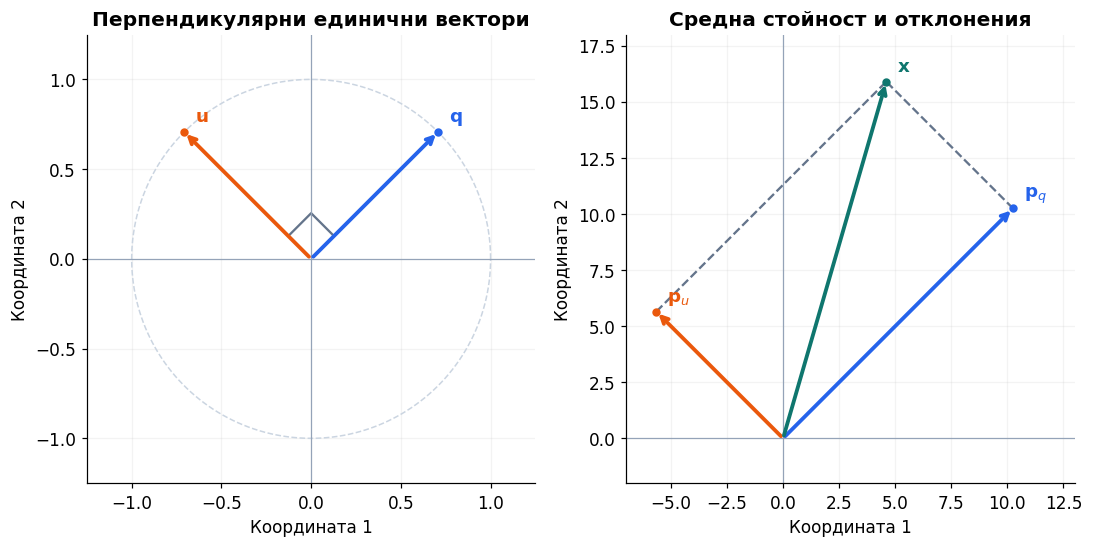

In [8]:
def draw_vector(ax, vector, label, color, offset=(7, 7)):
    ax.annotate('', xy=vector, xytext=(0, 0),
                arrowprops={'arrowstyle': '->', 'color': color, 'lw': 2.5})
    ax.scatter(vector[0], vector[1], s=20, color=color, zorder=3)
    ax.annotate(label, xy=vector, xytext=offset, textcoords='offset points',
                color=color, fontsize=12)


fig, axes = plt.subplots(1, 2, figsize=(10, 5))
draw_vector(axes[0], q2, r'$\mathbf{q}$', blue)
draw_vector(axes[0], u2, r'$\mathbf{u}$', orange)
t = np.linspace(0, 2 * np.pi, 200)
axes[0].plot(np.cos(t), np.sin(t), '--', color='#cbd5e1', lw=1)
corner = 0.18 * np.array([q2, q2 + u2, u2])
axes[0].plot(corner[:, 0], corner[:, 1], color=gray, lw=1.5)
axes[0].set(xlim=(-1.25, 1.25), ylim=(-1.25, 1.25),
            title='Перпендикулярни единични вектори')

draw_vector(axes[1], mean2, r'$\mathbf{p}_q$', blue)
draw_vector(axes[1], deviation2, r'$\mathbf{p}_u$', orange)
draw_vector(axes[1], x2, r'$\mathbf{x}$', teal)
for endpoint in [mean2, deviation2]:
    axes[1].plot([endpoint[0], x2[0]], [endpoint[1], x2[1]], '--', color=gray)
axes[1].set(xlim=(-7, 13), ylim=(-2, 18), title='Средна стойност и отклонения')

for ax in axes:
    ax.axhline(0, color='#94a3b8', lw=0.8)
    ax.axvline(0, color='#94a3b8', lw=0.8)
    ax.set_aspect('equal')
    ax.set_xlabel('Координата 1')
    ax.set_ylabel('Координата 2')
    ax.grid(alpha=0.15)
plt.tight_layout()
plt.show()

## 4. Дължини, стандартни отклонения и ъгли

Връщаме се към всички $n$ вина. Колона $j$ на $Z$ е векторът на отклоненията $\mathbf d_j$. Дефинираме единичния вектор $\mathbf u_j=\mathbf d_j/\|\mathbf d_j\|$. Тогава

$$\|\mathbf d_j\|=\sqrt{n-1}\,s_j,\qquad
r_{jk}=\mathbf u_j^\top\mathbf u_k=\cos\theta_{jk},\qquad
\theta_{jk}=\arccos(r_{jk}).$$

Ако $U$ съдържа колоните $\mathbf u_j$, то $R=U^\top U$.

**Задача 4а.** Пресметнете дължините на колоните на $Z$, образувайте $U$ и проверете формулите. Намерете ъглите на фиксираната киселинност с плътността, pH и алкохола. Използвайте `np.clip(r, -1, 1)` преди `np.arccos` и `np.degrees` за превръщане в градуси.

При само две наблюдения всички центрирани колони лежат на една права; корелациите между непостоянните колони са $1$ или $-1$. Затова тук използваме цялата извадка.

In [9]:
lengths = np.linalg.norm(Z, axis=0)
U = Z / lengths
angles = np.degrees(np.arccos(np.clip(R, -1, 1)))

print('Дължини:', np.allclose(lengths, np.sqrt(n - 1) * s))
print('Корелации:', np.allclose(U.T @ U, R))
pd.DataFrame({'Норма на отклоненията': lengths,
              'Стандартно отклонение': s}, index=variables)

Дължини: True
Корелации: True


,Норма на отклоненията,Стандартно отклонение
fixed_acidity,64.009901,1.736990
pH,5.713251,0.155036
density,0.068872,0.001869
alcohol,39.875250,1.082065


**Задача 4б. Визуализация.** Два единични вектора с корелация $r$ имат равнинно представяне

$$\mathbf a=(1,0)^\top,\qquad
\mathbf b=(r,\sqrt{1-r^2})^\top.$$

То запазва нормите, скаларното произведение и ъгъла на първоначалните $n$-мерни вектори. Начертайте трите двойки от задача 4а в отделни панели. Добавете единична окръжност и означете ъгъла. Дъга с радиус $\rho$ се задава с $(\rho\cos t,\rho\sin t)$ за $0\leq t\leq\theta$.

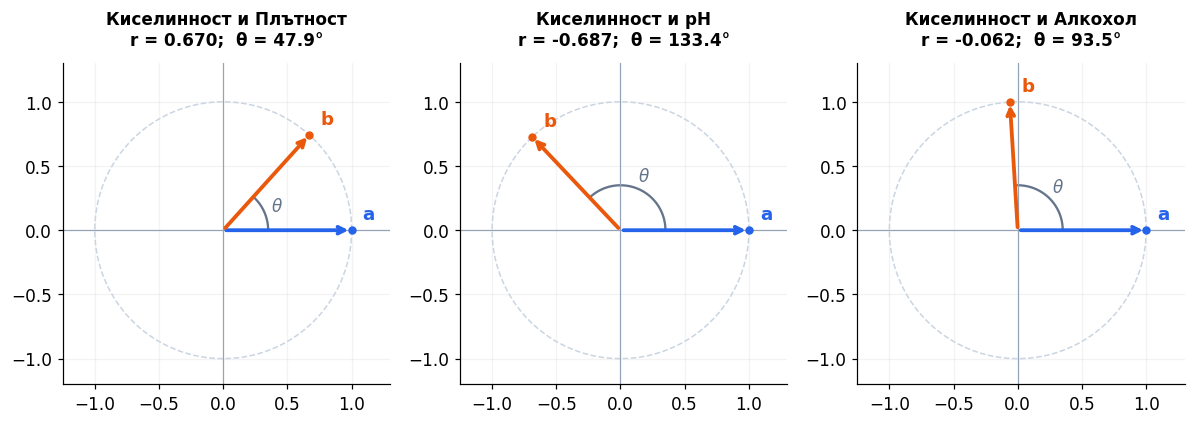

In [10]:
pairs = [(0, 2), (0, 1), (0, 3)]
fig, axes = plt.subplots(1, 3, figsize=(11, 4))
t = np.linspace(0, 2 * np.pi, 200)

for ax, (j, k) in zip(axes, pairs):
    r = np.clip(R[j, k], -1, 1)
    theta = np.arccos(r)
    a = np.array([1.0, 0.0])
    b = np.array([r, np.sqrt(1 - r**2)])
    draw_vector(ax, a, r'$\mathbf{a}$', blue)
    draw_vector(ax, b, r'$\mathbf{b}$', orange)
    ax.plot(np.cos(t), np.sin(t), '--', color='#cbd5e1', lw=1)
    arc = np.linspace(0, theta, 80)
    ax.plot(0.35 * np.cos(arc), 0.35 * np.sin(arc), color=gray)
    ax.text(0.46 * np.cos(theta / 2), 0.46 * np.sin(theta / 2),
            r'$\theta$', ha='center', va='center', color=gray)
    ax.axhline(0, color='#94a3b8', lw=0.8)
    ax.axvline(0, color='#94a3b8', lw=0.8)
    ax.set(xlim=(-1.25, 1.3), ylim=(-1.2, 1.3), aspect='equal')
    ax.set_title(f'{labels[j]} и {labels[k]}\nr = {r:.3f};  θ = {np.degrees(theta):.1f}°',
                 fontsize=11, pad=12)
    ax.grid(alpha=0.15)

plt.tight_layout()
plt.show()

## 5. Обобщена дисперсия и обем

Обобщената извадъчна дисперсия е $\det(S)$. За $D=\operatorname{diag}(s_1,\ldots,s_p)$ имаме

$$S=DRD,\qquad \det(S)=\det(R)\prod_{j=1}^p s_j^2.$$

Матрицата $G=Z^\top Z$ е матрица на Грам на векторите на отклоненията. Обемът $V$ на успоредника за $p=2$, паралелепипеда за $p=3$ или съответната $p$-мерна фигура удовлетворява

$$V^2=\det(G)=(n-1)^p\det(S).$$

За единичните вектори матрицата на Грам е $R$ и квадратът на обема е $\det(R)$. При два единични вектора лицето е $A=\sqrt{1-r^2}$. В общия случай $0\leq\det(R)\leq1$.

**Задача 5а.** Пресметнете $\det(S),\det(R)$ и $V$. Проверете връзката между детерминантите. За първите две колони на $U$ проверете, че лицето, получено от матрицата на Грам, е $\sqrt{1-r_{12}^2}$. Малка стойност на $\det(S)$ сама по себе си не доказва почти линейна зависимост, защото зависи от мерните единици.

In [11]:
det_S = np.linalg.det(S)
det_R = np.linalg.det(R)
volume = np.sqrt(np.linalg.det(Z.T @ Z))

pair = U[:, :2]
area = np.sqrt(np.linalg.det(pair.T @ pair))

print('det(S) =', det_S)
print('det(R) =', det_R)
print('Обем V =', volume)
print('Връзка между детерминантите:',
      np.isclose(det_S, det_R * np.prod(s**2), rtol=1e-10, atol=0))
print('Формула за обема:', np.isclose(volume, (n - 1)**(p / 2) * np.sqrt(det_S)))
print('Формула за лицето:', np.isclose(area, np.sqrt(1 - R[0, 1]**2)))

det(S) = 3.936569883463357e-08
det(R) = 0.13273009967910226
Обем V = 365.8967253279262
Връзка между детерминантите: True
Формула за обема: True
Формула за лицето: True


**Задача 5б. Визуализация.** Използвайте равнинните вектори $\mathbf a,\mathbf b$ от задача 4б за фиксираната киселинност и pH. Оцветете успоредника с върхове $\mathbf0,\mathbf a,\mathbf a+\mathbf b,\mathbf b$. До него начертайте случая $\mathbf b=\mathbf a$, при който лицето е нула. Посочете лицето във всеки панел. Използвайте `ax.fill` и еднакъв мащаб по осите.

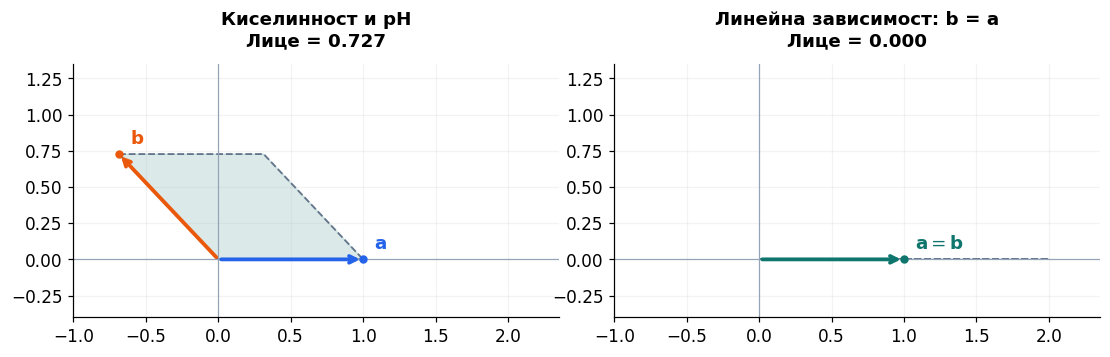

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
correlations = [R[0, 1], 1.0]
titles = ['Киселинност и pH', 'Линейна зависимост: b = a']

for ax, r, title in zip(axes, correlations, titles):
    a = np.array([1.0, 0.0])
    b = np.array([r, np.sqrt(1 - r**2)])
    vertices = np.array([[0, 0], a, a + b, b, [0, 0]])
    ax.fill(vertices[:, 0], vertices[:, 1], color=teal, alpha=0.15)
    ax.plot(vertices[:, 0], vertices[:, 1], '--', color=gray, lw=1.2)
    if r == 1:
        draw_vector(ax, a, r'$\mathbf{a}=\mathbf{b}$', teal)
    else:
        draw_vector(ax, a, r'$\mathbf{a}$', blue)
        draw_vector(ax, b, r'$\mathbf{b}$', orange)
    ax.axhline(0, color='#94a3b8', lw=0.8)
    ax.axvline(0, color='#94a3b8', lw=0.8)
    ax.set(xlim=(-1, 2.35), ylim=(-0.4, 1.35), aspect='equal')
    ax.set_title(f'{title}\nЛице = {np.sqrt(1 - r**2):.3f}', fontsize=12, pad=12)
    ax.grid(alpha=0.15)

plt.tight_layout()
plt.show()

## 6. Промяна на началото, мащаба и броя на колоните

Нека $x'_{ij}=c_jx_{ij}+b_j$, където $c_j>0$, и $C=\operatorname{diag}(c_1,\ldots,c_p)$. Тогава

$$S'=CSC,\qquad \det(S')=\det(S)\prod_{j=1}^p c_j^2,\qquad R'=R.$$

Константите $b_j$ не променят ковариациите. При добавяне на точно копие на колона новите колони са линейно зависими и детерминантите на двете матрици са нула. Рангът е броят линейно независими колони; за центрираната матрица $\operatorname{rank}(Z)\leq\min(p,n-1)$.

**Задача 6а.** Използвайте отделно копие на `data` за всеки случай: умножете плътността по $1000$; добавете $1$ към плътността; добавете копие на плътността като пета колона. Съставете таблица с броя колони, ранга на центрираната матрица и двете детерминанти. Проверете предсказаните промени. При линейна зависимост числената детерминанта може да е малка ненулева стойност поради закръгляване.

In [13]:
scaled = data.copy()
scaled['density'] *= 1000
shifted = data.copy()
shifted['density'] += 1
duplicated = data.copy()
duplicated['density_copy'] = duplicated['density']

cases = {'Изходни данни': data, 'Плътност × 1000': scaled,
         'Плътност + 1': shifted, 'Копие на плътността': duplicated}
rows = []
for name, frame in cases.items():
    centered = frame.to_numpy() - frame.mean().to_numpy()
    rows.append([name, frame.shape[1], np.linalg.matrix_rank(centered),
                 np.linalg.det(frame.cov()), np.linalg.det(frame.corr())])

print('Мащабиране на детерминантата:',
      np.isclose(np.linalg.det(scaled.cov()) / det_S, 1000**2))
print('Корелации след мащабиране:', np.allclose(scaled.corr(), R))
print('Ковариации след преместване:', np.allclose(shifted.cov(), S))
pd.DataFrame(rows, columns=['Случай', 'Брой колони', 'Ранг', 'det(S)', 'det(R)'])

Мащабиране на детерминантата: True
Корелации след мащабиране: True
Ковариации след преместване: True


,Случай,Брой колони,Ранг,det(S),det(R)
0,Изходни данни,4,4,3.936570e-08,0.13273
1,Плътност × 1000,4,4,3.936570e-02,0.13273
2,Плътност + 1,4,4,3.936570e-08,0.13273
3,Копие на плътността,5,4,0.000000e+00,0.00000


**Задача 6б. Визуализация.** В три панела начертайте алкохола спрямо плътността: преди промяната, след умножение по $1000$ и след добавяне на $1$. Надпишете осите с преобразуваните величини. Сравнете подредбата на точките и числата по хоризонталните оси.

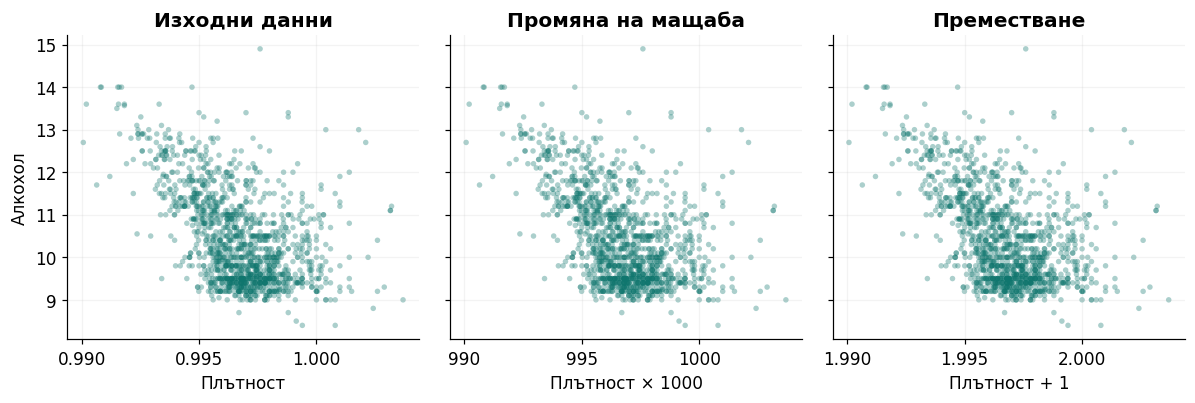

In [14]:
fig, axes = plt.subplots(1, 3, figsize=(11, 3.8), sharey=True)
frames = [data, scaled, shifted]
xlabels = ['Плътност', 'Плътност × 1000', 'Плътност + 1']
titles = ['Изходни данни', 'Промяна на мащаба', 'Преместване']

for ax, frame, xlabel, title in zip(axes, frames, xlabels, titles):
    ax.scatter(frame['density'], frame['alcohol'], s=13, alpha=0.35,
               color=teal, edgecolors='none')
    ax.set(xlabel=xlabel, title=title)
    ax.ticklabel_format(axis='x', style='plain', useOffset=False)
    ax.locator_params(axis='x', nbins=3)
    ax.grid(alpha=0.15)
axes[0].set_ylabel('Алкохол')
plt.tight_layout()
plt.show()

## 7. Стандартизация

Стандартизираната матрица $W$ се определя чрез

$$w_{ij}=\frac{x_{ij}-\bar x_j}{s_j}.$$

Всяка колона има средна стойност $0$, извадъчно стандартно отклонение $1$ и дължина $\sqrt{n-1}$. Следователно

$$\frac{W^\top W}{n-1}=R,\qquad W=\sqrt{n-1}\,U.$$

Стандартизацията не превръща произволно разпределение в нормално.

**Задача 7а.** Пресметнете $W$ и проверете посочените свойства. Обяснете разликата между стандартизиране на колона и нормализиране до единична дължина.

In [15]:
W = Z / s
print('Средни стойности:', np.allclose(W.mean(axis=0), 0))
print('Стандартни отклонения:', np.allclose(W.std(axis=0, ddof=1), 1))
print('Ковариационна матрица:', np.allclose(W.T @ W / (n - 1), R))
print('Връзка с U:', np.allclose(W, np.sqrt(n - 1) * U))

Средни стойности: True
Стандартни отклонения: True
Ковариационна матрица: True
Връзка с U: True


**Задача 7б. Визуализация.** Начертайте хистограми на четирите стандартизирани колони с обща хоризонтална скала. Означете $0$ с плътна вертикална линия и $-1,1$ с пунктир. Сравнете формите на разпределенията.

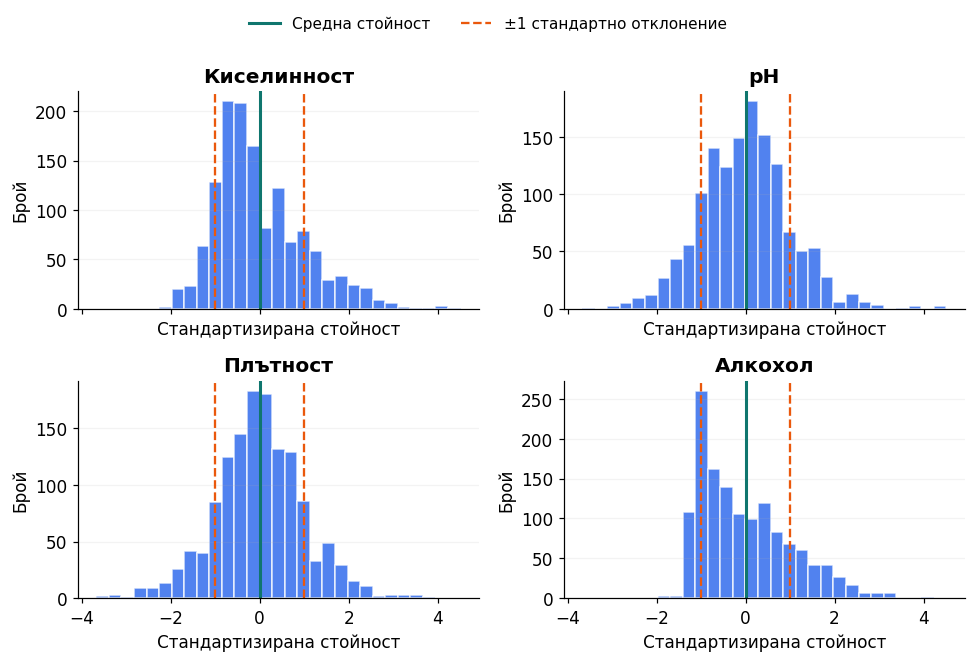

In [16]:
fig, axes = plt.subplots(2, 2, figsize=(9, 6), sharex=True)
bins = np.linspace(W.min(), W.max(), 30)

for j, ax in enumerate(axes.flat):
    ax.hist(W[:, j], bins=bins, color=blue, alpha=0.8, edgecolor='white')
    ax.axvline(0, color=teal, lw=2, label='Средна стойност')
    ax.axvline(-1, color=orange, ls='--', lw=1.5, label='±1 стандартно отклонение')
    ax.axvline(1, color=orange, ls='--', lw=1.5)
    ax.set(title=labels[j], xlabel='Стандартизирана стойност', ylabel='Брой')
    ax.grid(axis='y', alpha=0.15)
handles, legend_labels = axes[0, 0].get_legend_handles_labels()
fig.legend(handles, legend_labels, loc='upper center', ncol=2, frameon=False,
           fontsize=10, bbox_to_anchor=(0.5, 1.01))
plt.tight_layout(rect=(0, 0, 1, 0.94))
plt.show()

## 8. Връзка с линейната регресия

Нека $F\in\mathbb R^{n\times k}$ съдържа всичките $k=11$ физикохимични показателя, а $\mathbf y$ — стойностите на `quality`. Използваме метода на най-малките квадрати (OLS). Оценката `quality` е порядкова; линейният модел служи като числово приближение.

За колона $j$ на $F$ означаваме средната стойност с $\mu_j$ и извадъчното стандартно отклонение с $t_j$. Дефинираме $F^*_{ij}=(F_{ij}-\mu_j)/t_j$, $A=[\mathbf1,F]$ и $B=[\mathbf1,F^*]$. При пълен ранг на колоните

$$\hat{\boldsymbol\beta}
=\underset{\boldsymbol\beta}{\arg\min}\|\mathbf y-A\boldsymbol\beta\|^2
=(A^\top A)^{-1}A^\top\mathbf y,\qquad
\hat{\mathbf y}=A\hat{\boldsymbol\beta},\qquad
\mathbf e=\mathbf y-\hat{\mathbf y},\qquad A^\top\mathbf e=\mathbf0.$$

За стандартизирания модел означаваме коефициентите с $\hat{\boldsymbol\gamma}$. Двете параметризации са свързани чрез

$$\hat\beta_j=\frac{\hat\gamma_j}{t_j}\ (j\geq1),\qquad
\hat\beta_0=\hat\gamma_0-\sum_{j=1}^k\mu_j\frac{\hat\gamma_j}{t_j},\qquad
A\hat{\boldsymbol\beta}=B\hat{\boldsymbol\gamma}.$$

**Задача 8а.** Постройте $A$ и $B$ и оценете двата модела с `np.linalg.lstsq`. Сравнете оценените стойности и проверете връзката между коефициентите. Проверете $B^\top\mathbf e\approx\mathbf0$ с абсолютен толеранс $10^{-8}$. Обяснете защо стандартизацията запазва проекцията на $\mathbf y$ върху пространството на колоните на модела.

In [17]:
predictors = [name for name in wine.columns if name != 'quality']
F = wine[predictors].to_numpy()
y = wine['quality'].to_numpy()
mu = F.mean(axis=0)
t = F.std(axis=0, ddof=1)
F_scaled = (F - mu) / t

A = np.column_stack([np.ones(n), F])
B = np.column_stack([np.ones(n), F_scaled])
beta = np.linalg.lstsq(A, y, rcond=None)[0]
gamma = np.linalg.lstsq(B, y, rcond=None)[0]
fitted = A @ beta
fitted_scaled = B @ gamma
residuals = y - fitted_scaled

slopes = gamma[1:] / t
intercept = gamma[0] - mu @ slopes

print('Оценени стойности:', np.allclose(fitted, fitted_scaled))
print('Коефициенти:', np.allclose(beta, np.r_[intercept, slopes]))
print('Ортогоналност:', np.allclose(B.T @ residuals, 0, atol=1e-8))

Оценени стойности: True
Коефициенти: True
Ортогоналност: True


**Задача 8б. Визуализация.** В първи панел начертайте оценените стойности от стандартизирания модел спрямо тези от първоначалния модел и добавете правата $y=x$. Във втори панел начертайте остатъците спрямо оценените стойности и добавете хоризонталната права $e=0$.

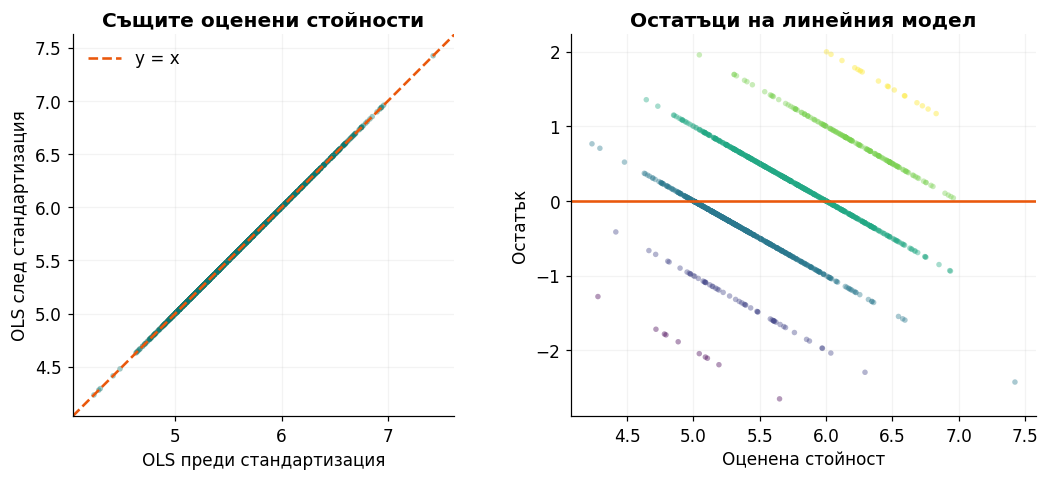

In [19]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4.5))
axes[0].scatter(fitted, fitted_scaled, s=13, color=teal, alpha=0.4,
                edgecolors='none')
limits = [fitted.min() - 0.2, fitted.max() + 0.2]
axes[0].plot(limits, limits, '--', color=orange, lw=1.7, label='y = x')
axes[0].set(xlim=limits, ylim=limits, aspect='equal',
            xlabel='OLS преди стандартизация', ylabel='OLS след стандартизация',
            title='Същите оценени стойности')
axes[0].legend(frameon=False)

axes[1].scatter(fitted_scaled, residuals, s=13, c=y, alpha=0.4,
                edgecolors='none')
axes[1].axhline(0, color=orange, lw=1.7)
axes[1].set(xlabel='Оценена стойност', ylabel='Остатък',
            title='Остатъци на линейния модел')
for ax in axes:
    ax.grid(alpha=0.15)
plt.tight_layout()
plt.show()